# Understanding U.S. bird flu outbreak patterns
Executed observational investigation using frozen official APHIS data, retrieved **6 November 2026**.

The question is what patterns appear in poultry detections and what might explain them. Detection records, affected flocks and affected birds are distinct units. This notebook executes the analysis in `scripts/analyze.py`; the complete methods and critical interpretation are in `REPORT.html`.

## 1. Hypotheses and provenance
The analysis plan was written before computing summaries; it was informed by source schemas and literature, not registered publicly. H1 tests spring/autumn versus summer, H2 production-group seasonal composition, H3 state/year composition, and H4 an exploratory wild-bird lead. Raw snapshots are never silently refreshed.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image, HTML
ROOT = Path.cwd()
assert (ROOT / 'analysis-plan.txt').exists()
sys.path.insert(0, str(ROOT / 'scripts'))
import analyze
print((ROOT / 'analysis-plan.txt').read_text())
display(pd.DataFrame(analyze.verify_sources())[['path', 'retrieved_at', 'sha256']])

Prospective analysis plan written 2026-11-06 UTC, before computing outbreak summaries.
Existing workspace contained an APHIS-derived mirrored poultry CSV; its first records/schema were inspected only. Literature and official page descriptions informed these hypotheses. This is an analysis plan, not a registered preregistration.
H1: Recorded poultry flock detections per calendar day are higher in spring (Mar-May) and autumn (Sep-Nov) than summer (Jun-Aug). Winter is Dec-Feb. Fit monthly Poisson counts with log(days) offset, season and year indicators; use HAC covariance (3 monthly lags). Report overdispersion, year-specific contrasts, and sensitivity excluding incomplete calendar years. Tests are observational detection-intensity contrasts, not infection rates.
H2: Commercial and backyard-labelled records have different seasonal distributions. Report seasonal shares and Cramer's V; permute type labels within year (4,999 permutations) to account for annual composition. Rows labelled WOAH

,path,retrieved_at,sha256
0,data/raw/wild_birds.csv,2026-11-06T06:51:21.365164+00:00,008c86d461663f22e0d0f717f597f7a96013f42e277cc3...
1,data/raw/states.zip,2026-11-06T06:51:21.783085+00:00,7bc773d83c01b6df69b8aada9c2b5983d97f22f4551947...
2,sources/aphis_poultry.html,2026-11-06T06:51:24.988484+00:00,b7bad6de89e2d1acac2a0b3747e95c15d4fc8ee53fa7ae...
3,sources/aphis_wild.html,2026-11-06T06:51:27.145632+00:00,1262c2292934a633c4ba623affc12226fb96dae0c1f3c2...
4,data/raw/A Table by Confirmation Date.csv,2026-11-06T06:59:24.693223+00:00,5a6ffbc475ba5c2bd51ecbed48e9ad4985d681e4a105af...


## 2. Clean and validate
The poultry export is UTF-16 and tab-delimited. Control-area release dates are column headings; confirmation dates are row fields. We validate one bird-count cell per event and fill repeated Tableau row headings. We preserve repeated public signatures because they may represent distinct flocks or wild birds.

The primary poultry outcome excludes WOAH Non-Poultry. The unqualified WOAH Poultry production label serves as a backyard-poultry proxy, supported by APHIS reporting conventions. It is not an independent backyard flag.

In [2]:
p, w, validation = analyze.clean()
display(pd.Series(validation, name='Validation'))
display(p.head())
display(p.groupby('group').agg(events=('date','size'), affected_birds=('birds_affected','sum')))

poultry_rows                                                                                  2300
wild_rows                                                                                    20539
poultry_date_min                                                                        2022-02-08
poultry_date_max                                                                        2026-11-04
wild_date_min                                                                           2022-01-12
wild_date_max                                                                           2026-10-27
poultry_exact_signatures_repeated                                                               10
poultry_repeated_event_labels                                                                    0
poultry_repeated_premises_labels_across_dates                                                    0
wild_exact_signatures_repeated                                                                7447
wild_missi

,date,state,county,premises_label,production,birds_affected,control_area_release_heading,group,year,month,season,period,is_poultry
0,2026-11-04,Oregon,Clackamas,Clackamas 04,Commercial Table Egg Layer,94200,Active,Commercial,2026,11,Autumn,2026-11,True
1,2026-11-03,California,San Benito,San Benito 02,WOAH Non-Poultry,20,NA,WOAH Non-Poultry,2026,11,Autumn,2026-11,False
2,2026-11-02,California,Sacramento,Sacramento 11,WOAH Non-Poultry,160,NA,WOAH Non-Poultry,2026,11,Autumn,2026-11,False
3,2026-10-30,Washington,Yakima,Yakima 07,WOAH Non-Poultry,10,NA,WOAH Non-Poultry,2026,10,Autumn,2026-10,False
4,2026-10-29,California,Sacramento,Sacramento 10,WOAH Non-Poultry,30,NA,WOAH Non-Poultry,2026,10,Autumn,2026-10,False


,events,affected_birds
group,,
Backyard poultry proxy,286,2488425
Commercial,1060,209088850
Market / sales,80,41174
WOAH Non-Poultry,874,56997


## 3. Explore the calendar and choose comparable months
Zero reported rows are zero detections in this snapshot, not proof of zero infections. We exclude February 2022 and November 2026 from inference. All records remain in full-window descriptive summaries. Seasonal contrasts use a calendar-day offset, never a susceptible-flock denominator.

In [3]:
m = analyze.monthly(p, w)
complete = m.loc['2022-03-01':'2026-10-01']
print('Complete analysis months:', len(complete))
display(complete.groupby(['year','season'], observed=True).agg(events=('poultry','sum'), days=('days','sum')))

Complete analysis months: 56


events  days
year season              
2022 Summer      24    92
     Autumn     120    91
     Winter      30    31
     Spring     212    92
2023 Summer       3    92
     Autumn      96    91
     Winter      80    90
     Spring      32    92
2024 Summer      19    92
     Autumn      52    91
     Winter     103    91
     Spring      28    92
2025 Summer       4    92
     Autumn     132    91
     Winter     213    90
     Spring      52    92
2026 Summer      12    92
     Autumn      31    61
     Winter      80    59
     Spring      94    92

## 4. Execute the hypothesis tests
Poisson seasonal models use year effects and HAC(3) covariance. A negative-binomial sensitivity addresses overdispersion. Seasonal-type tests permute type within year, and the geographic test permutes year across events; outbreak clustering limits exchangeability. Holm adjustment covers the two planned H1 contrasts plus H2/H3. All sensitivities and H4 are exploratory.

In [4]:
h = analyze.hypotheses(p, w, m)
display(pd.DataFrame(h['H1']))
print('Holm adjusted primary p:', h['holm_p'])
print('Poisson dispersion:', h['H1_dispersion'])
display(pd.DataFrame(h['H1_negative_binomial']))
display(pd.DataFrame({k:h[k] for k in ['H2','H2_full_years','H2_including_nonpoultry','H3','H3_full_years']}).T)
print('Exploratory wild-bird lag:', json.dumps(h['H4_exploratory'], indent=2))

,season,ratio,ci_low,ci_high,p_two_sided
0,Spring,6.741935,3.580262,12.695635,3.425836e-09
1,Autumn,7.457093,4.090478,13.594556,5.461880e-11
2,Winter,11.486391,5.613912,23.501826,2.336126e-11


Holm adjusted primary p: {'H1_spring': 1.0277509204455243e-08, 'H1_autumn': 2.1847518443984628e-10, 'H2': 0.1648, 'H3': 0.0004}
Poisson dispersion: 15.564363695212842


,season,ratio,ci_low,ci_high,p_two_sided
0,Spring,5.933921,3.217054,10.945239,1.192430e-08
1,Autumn,8.245460,3.938259,17.263367,2.194908e-08
2,Winter,12.420350,5.522685,27.932989,1.110770e-09


,chi2,cramers_v,permutation_p,n,minimum_expected,cells_expected_under_5,permutations
H2,5.568868,0.064538,0.1648,1337.0,10.909499,0.0,4999.0
H2_full_years,27.138315,0.189466,0.0002,756.0,3.642857,1.0,4999.0
H2_including_nonpoultry,7.550078,0.058555,0.2234,2202.0,49.638510,0.0,4999.0
H3,933.624857,0.405855,0.0002,1417.0,0.142555,166.0,4999.0
H3_full_years,446.912394,0.523943,0.0002,814.0,0.248157,91.0,4999.0


Exploratory wild-bird lag: {
  "beta": -0.11813234171325972,
  "ci_low": -0.33736023205144233,
  "ci_high": 0.10109554862492291,
  "p": 0.2909046933329015,
  "n_months": 55,
  "first_difference": {
    "beta": 0.07878276491253479,
    "ci_low": -0.1508217387347633,
    "ci_high": 0.3083872685598329,
    "p": 0.5012589178712934,
    "n_months": 54
  },
  "collection_date_sensitivity": {
    "beta": 0.28088431748023557,
    "ci_low": -0.04839487746779053,
    "ci_high": 0.6101635124282616,
    "p": 0.09454328809228972,
    "n_months": 55
  }
}


## 5. Investigate results that complicate the initial story
Winter has a high seasonal estimate: the important pattern is broader than spring and autumn. The commercial/backyard comparison changes when edge years are removed; a universal group difference would be misleading. Bird totals can be dominated by a few large egg-layer events.

Confirmation delays may exceed the proposed one-month wildlife warning interval. Missing collection dates and impossible negative intervals are flagged, rather than repaired by guessing. Collection-date sensitivities exclude impossible intervals and remain subject to retrospective availability bias.

In [5]:
display(pd.read_csv(ROOT/'results/h2_by_year.csv'))
display(pd.read_csv(ROOT/'results/season_by_year.csv'))
display(pd.read_csv(ROOT/'results/production_totals.csv').head(8))
print('Collection delay percentiles:', validation['wild_delay_quantiles_days'])
print('Collection delays over 30 days:', validation['wild_delay_over_30_days'])
print('Invalid collection-date tokens:', validation['wild_invalid_collection_tokens'])
print('Negative intervals:', validation['wild_negative_delay'])
print('Burden summary:', (ROOT/'results/descriptive.json').read_text())

,year,group,Autumn,Spring,Summer,Winter
0,2022,Backyard poultry proxy,36,37,10,5
1,2022,Commercial,83,175,14,25
2,2023,Backyard poultry proxy,13,21,0,21
3,2023,Commercial,82,7,0,57
4,2024,Backyard poultry proxy,5,4,1,12
5,2024,Commercial,45,22,14,90
6,2025,Backyard poultry proxy,39,8,0,29
7,2025,Commercial,93,19,3,171
8,2026,Backyard poultry proxy,5,17,3,20
9,2026,Commercial,26,67,6,52


,year,season,events,days,detections_per_day
0,2022,Summer,24,92,0.260870
1,2022,Autumn,120,91,1.318681
2,2022,Winter,30,31,0.967742
3,2022,Spring,212,92,2.304348
4,2023,Summer,3,92,0.032609
5,2023,Autumn,96,91,1.054945
6,2023,Winter,80,90,0.888889
7,2023,Spring,32,92,0.347826
8,2024,Summer,19,92,0.206522
9,2024,Autumn,52,91,0.571429


,production,events,birds
0,Commercial Table Egg Layer,139,154732800
1,Commercial Turkey Meat Bird,521,22479400
2,Commercial Broiler Production,84,15099200
3,Commercial Table Egg Pullets,27,10897500
4,WOAH Poultry,286,2488425
5,Commercial Duck Meat Bird,94,1429400
6,Commercial Upland Gamebird Producer,27,868840
7,Commercial Broiler Breeder,24,809000


Collection delay percentiles: {0.5: 15.0, 0.9: 151.0, 0.95: 257.0, 0.99: 308.40000000000146}
Collection delays over 30 days: 5230
Invalid collection-date tokens: {'Unknown': 277, '2/19/215': 1}
Negative intervals: 10
Burden summary: {
  "annual_poultry_events": {
    "2022": 394,
    "2023": 211,
    "2024": 202,
    "2025": 401,
    "2026": 218
  },
  "annual_all_events": {
    "2022": 718,
    "2023": 342,
    "2024": 316,
    "2025": 610,
    "2026": 314
  },
  "annual_poultry_birds": {
    "2022": 57798941,
    "2023": 21846360,
    "2024": 50648016,
    "2025": 54726122,
    "2026": 26599010
  },
  "top10_events_bird_share": 0.18000746239284648,
  "top1pct_events_bird_share": 0.23940445759528273,
  "top5_states_by_events": [
    {
      "state": "Minnesota",
      "events": 187,
      "birds": 10974130
    },
    {
      "state": "Indiana",
      "events": 184,
      "birds": 10578470
    },
    {
      "state": "South Dakota",
      "events": 159,
      "birds": 8330610
    },
  

## 6. Generate and inspect the figures
Publication assets are saved as 300-dpi PNG and editable vector SVG. State maps include Alaska, Hawaii and Puerto Rico insets. Geographic colors represent counts, not risks. All figures below are generated by the executed code.

01_timeline.png


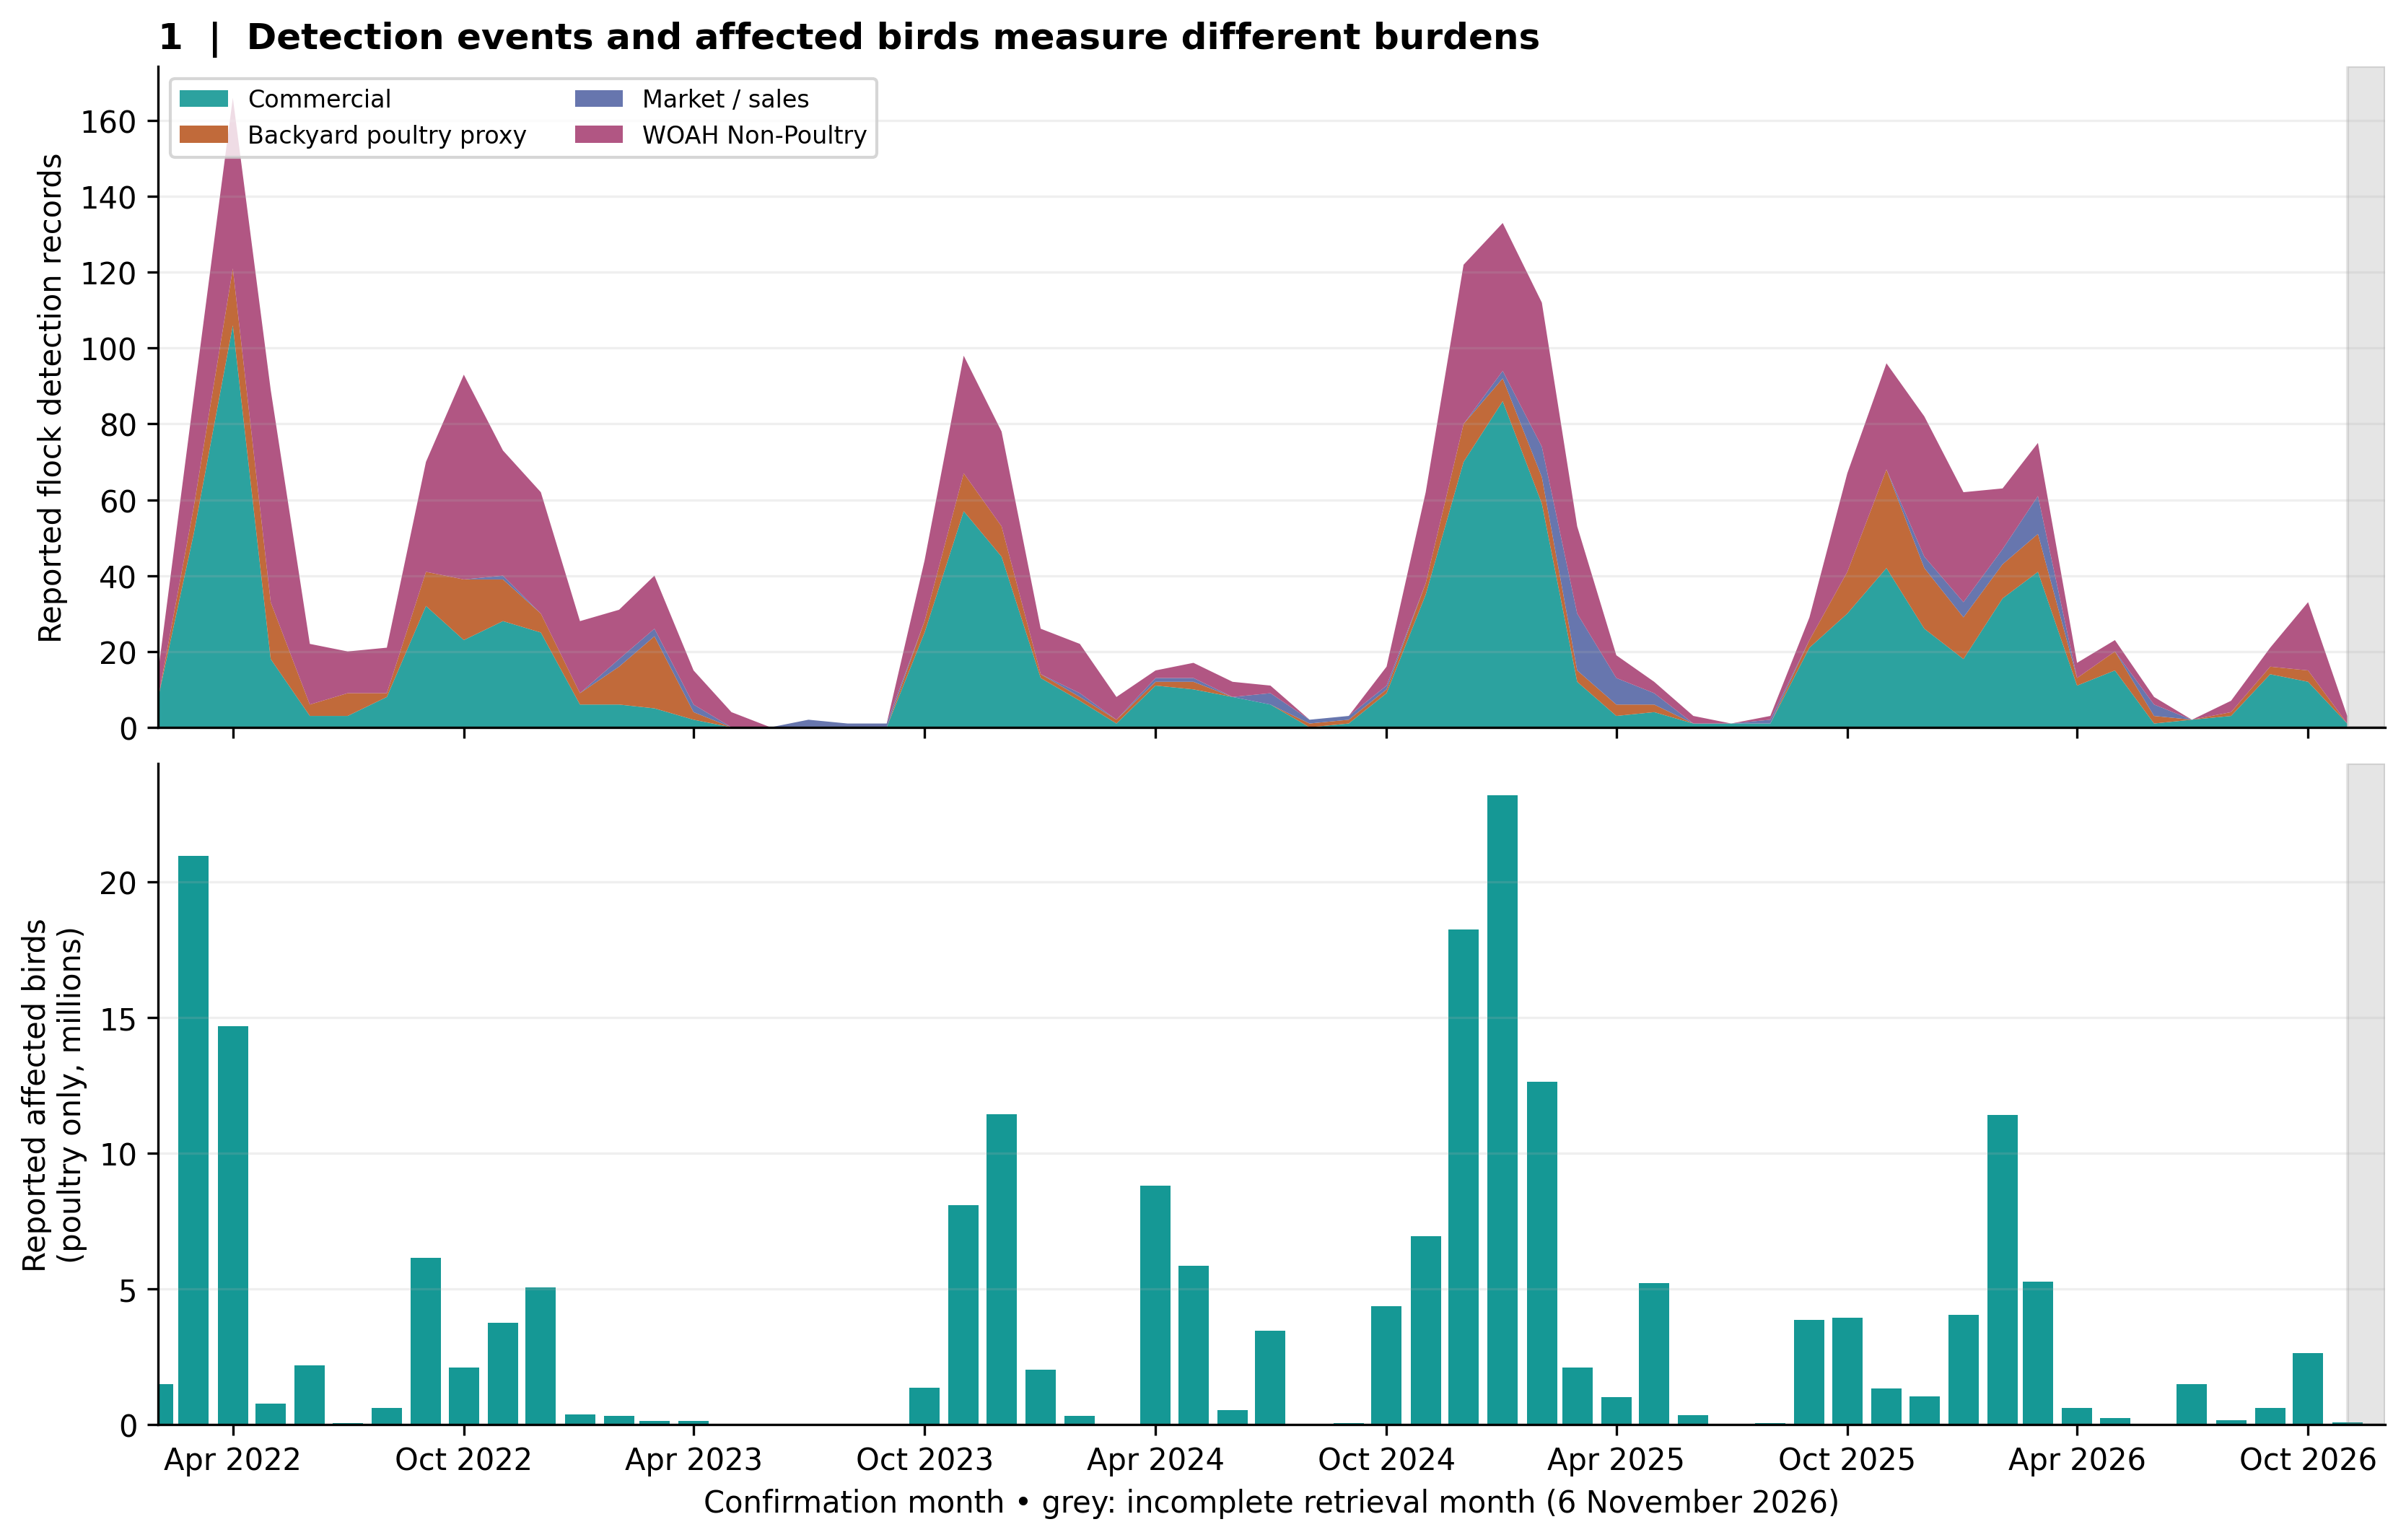

02_month_year_heatmap.png


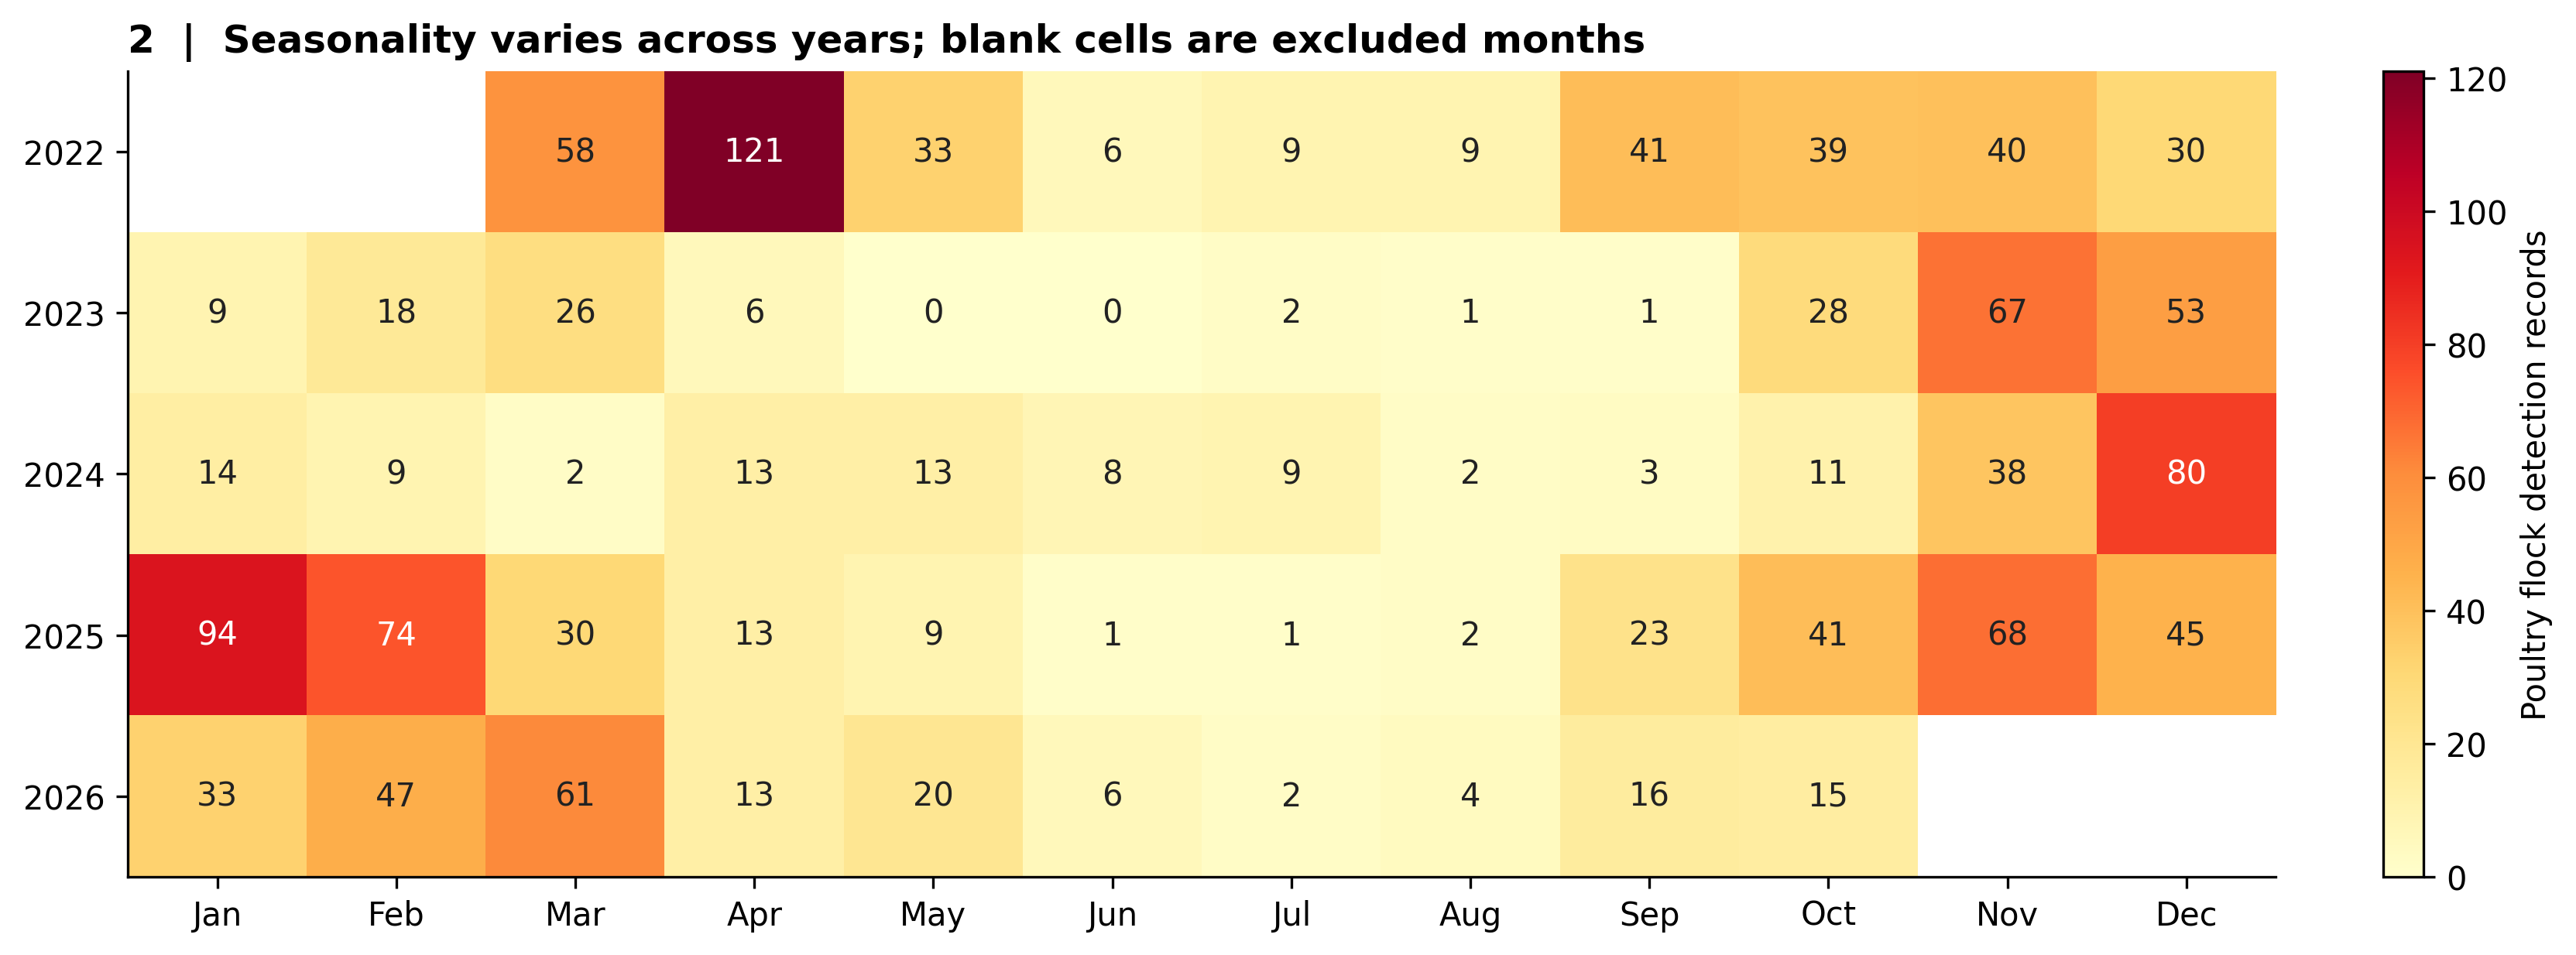

03_seasonal_tests.png


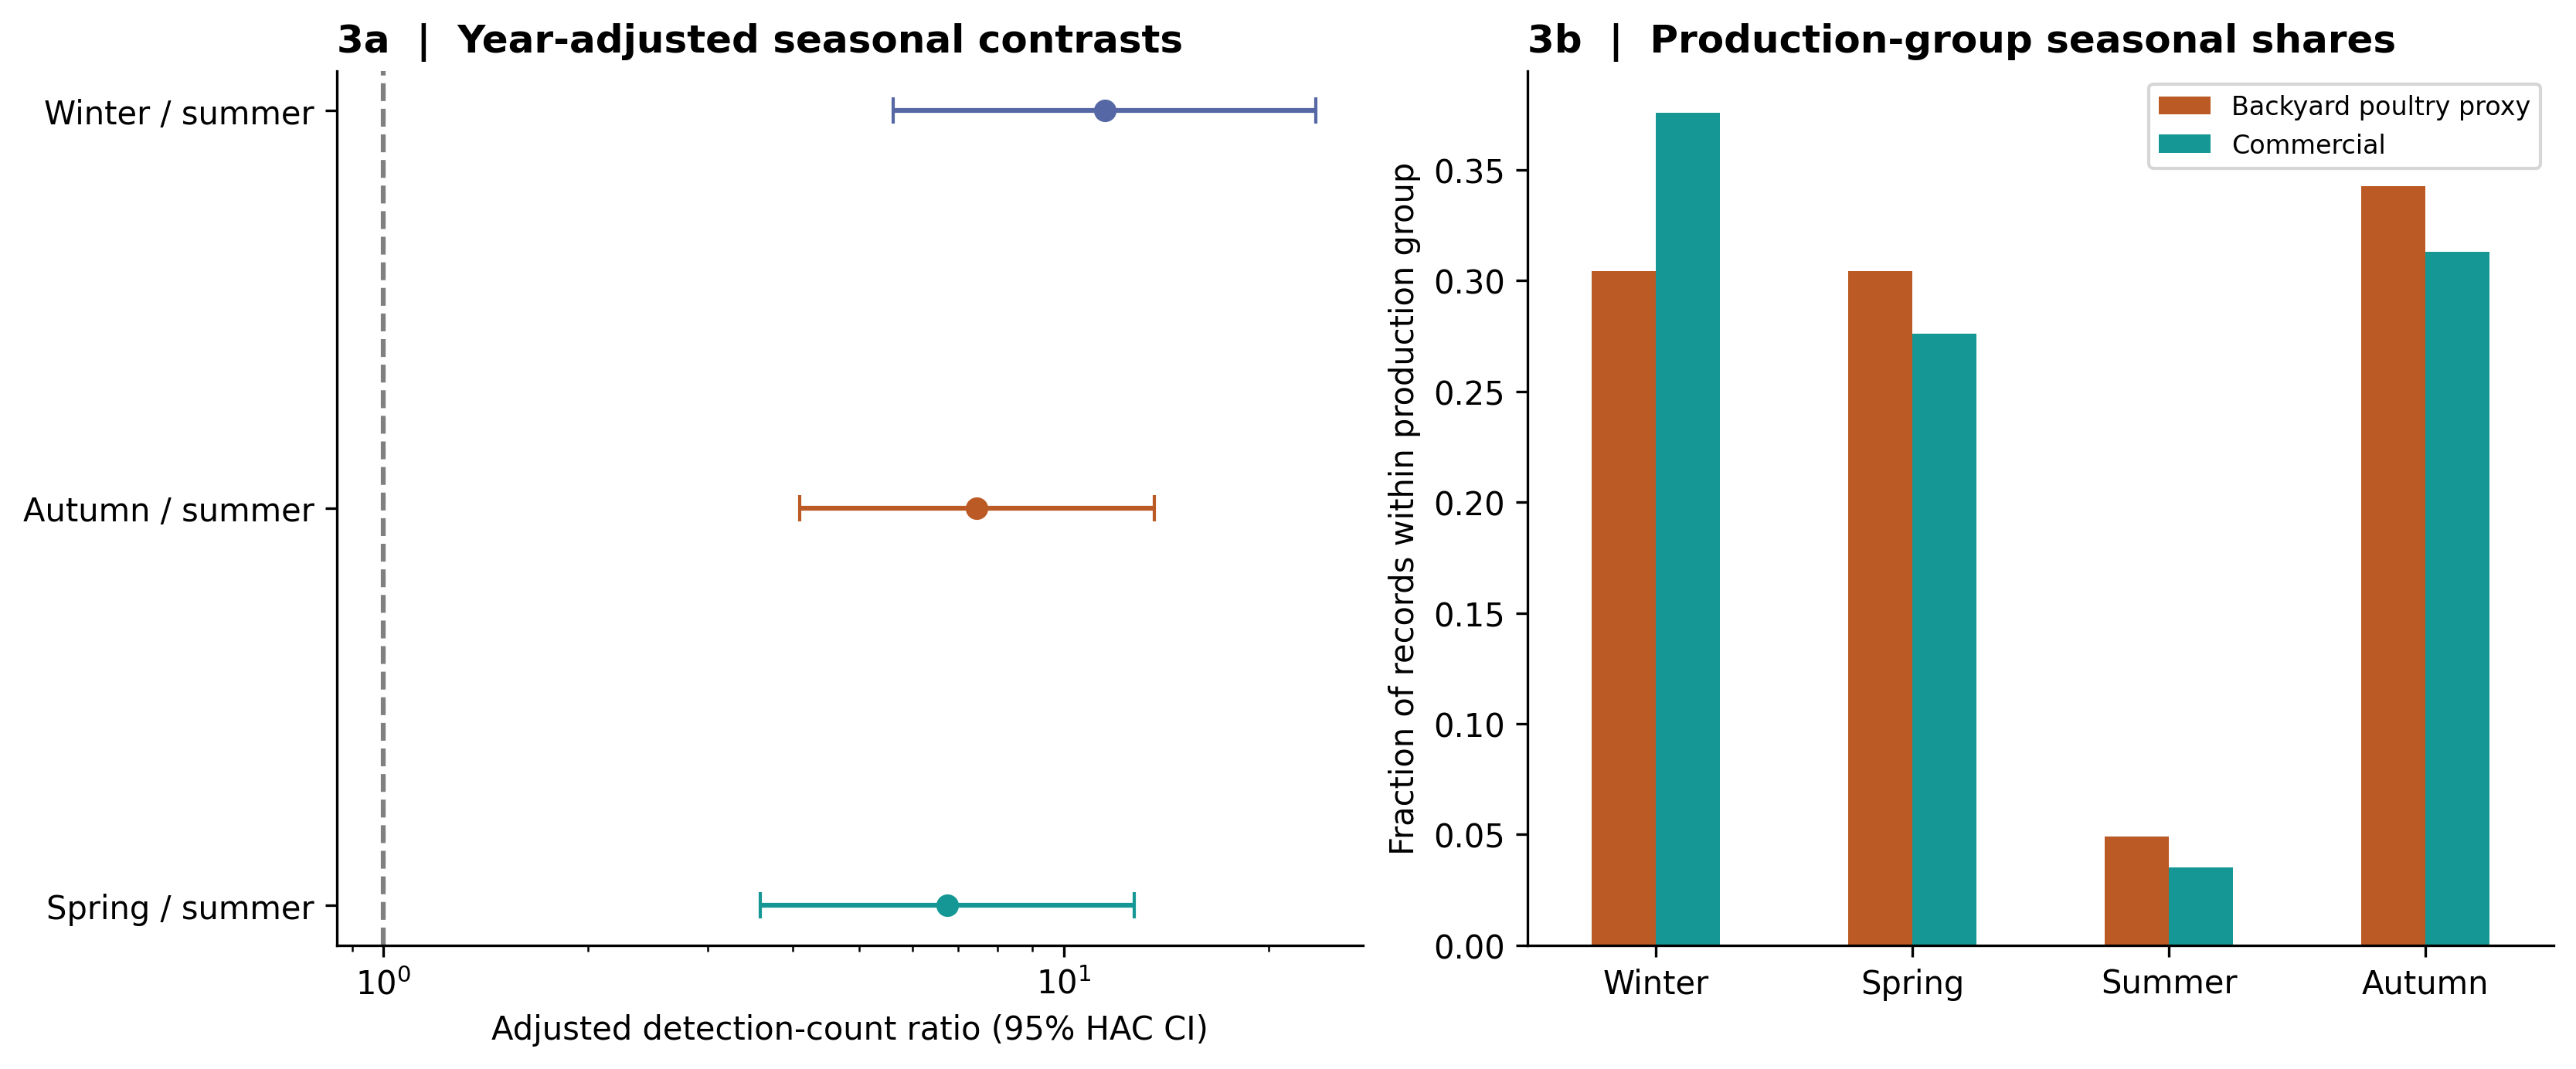

04_geography.png


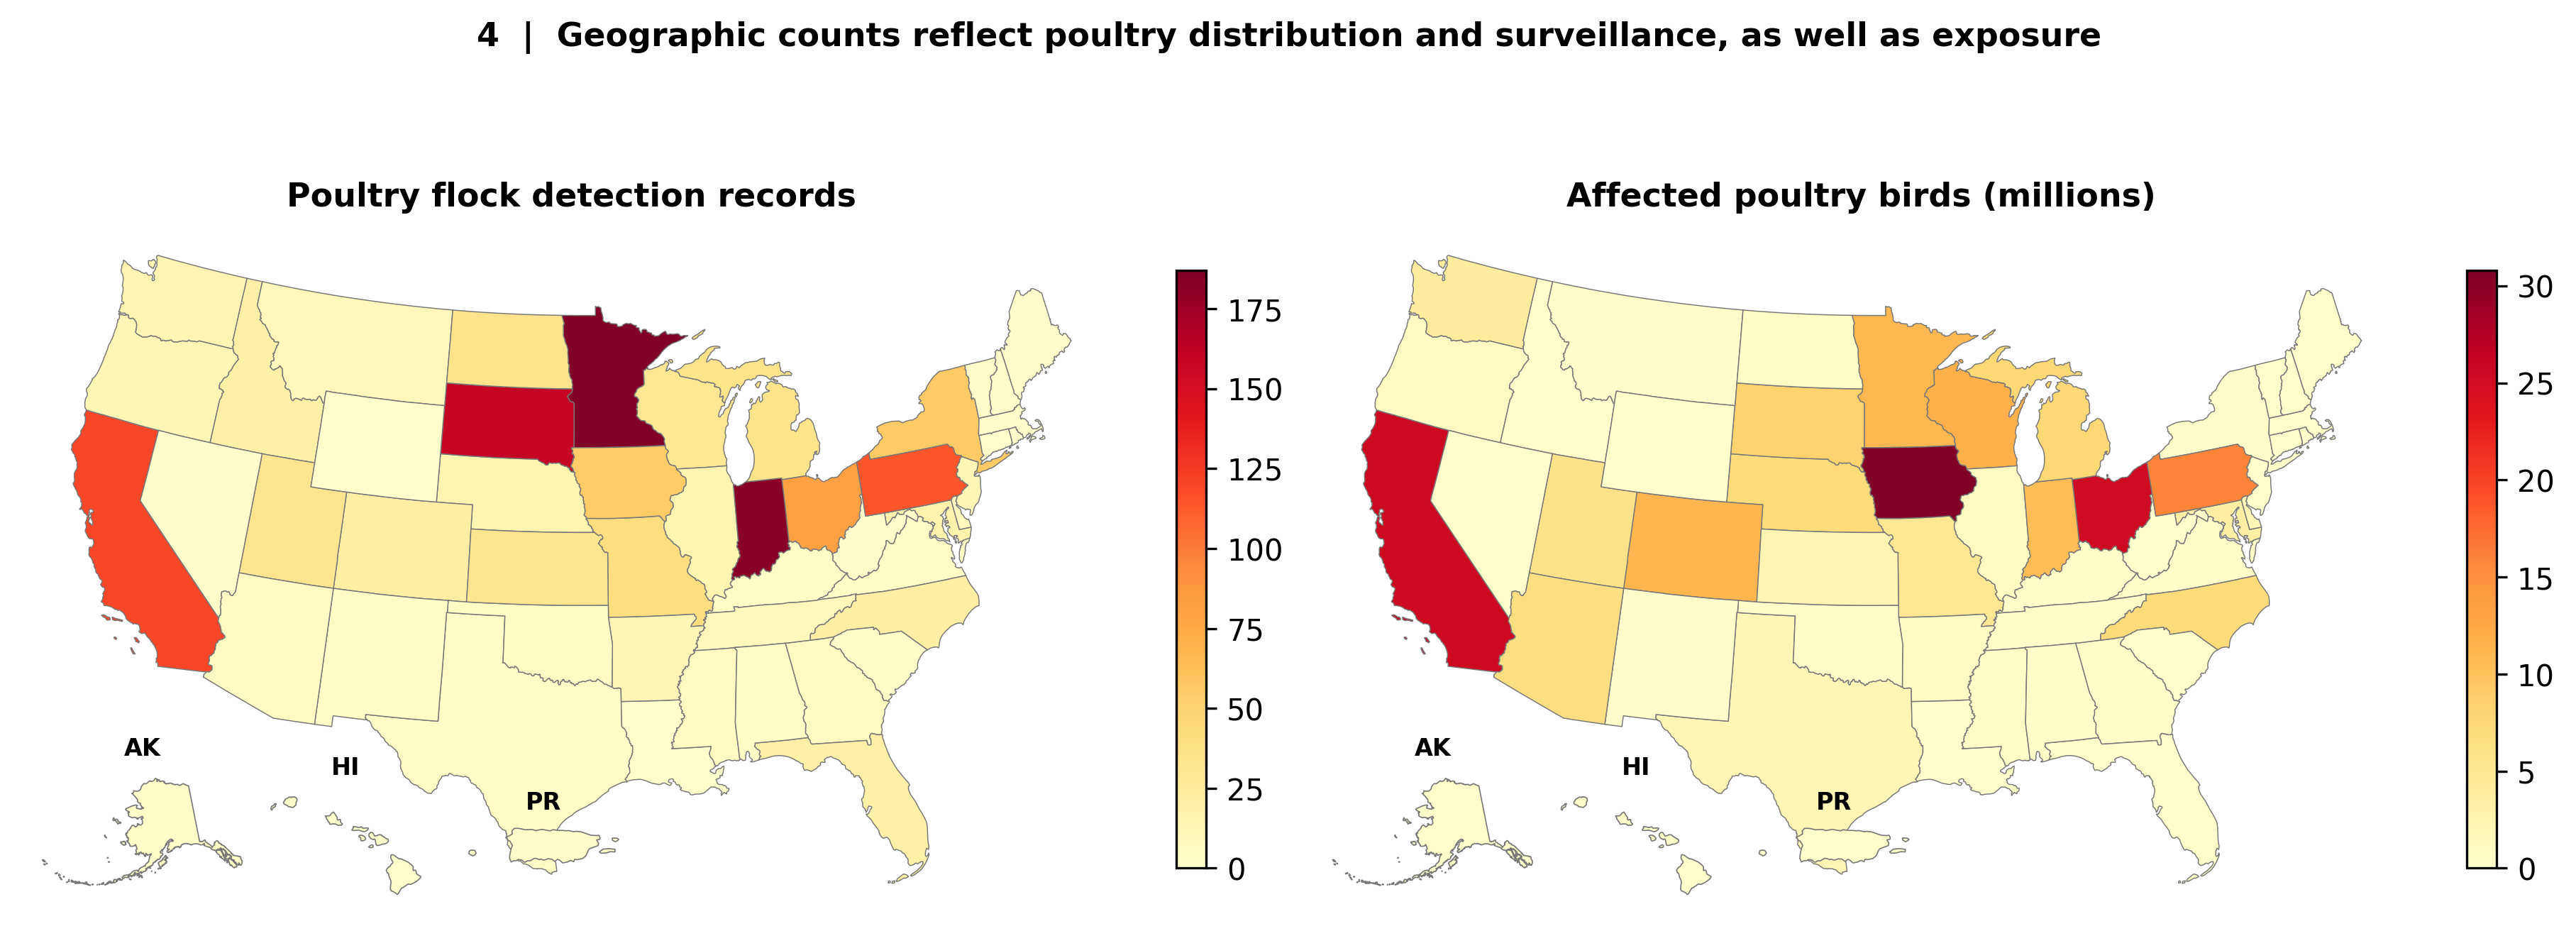

05_wild_poultry_lags.png


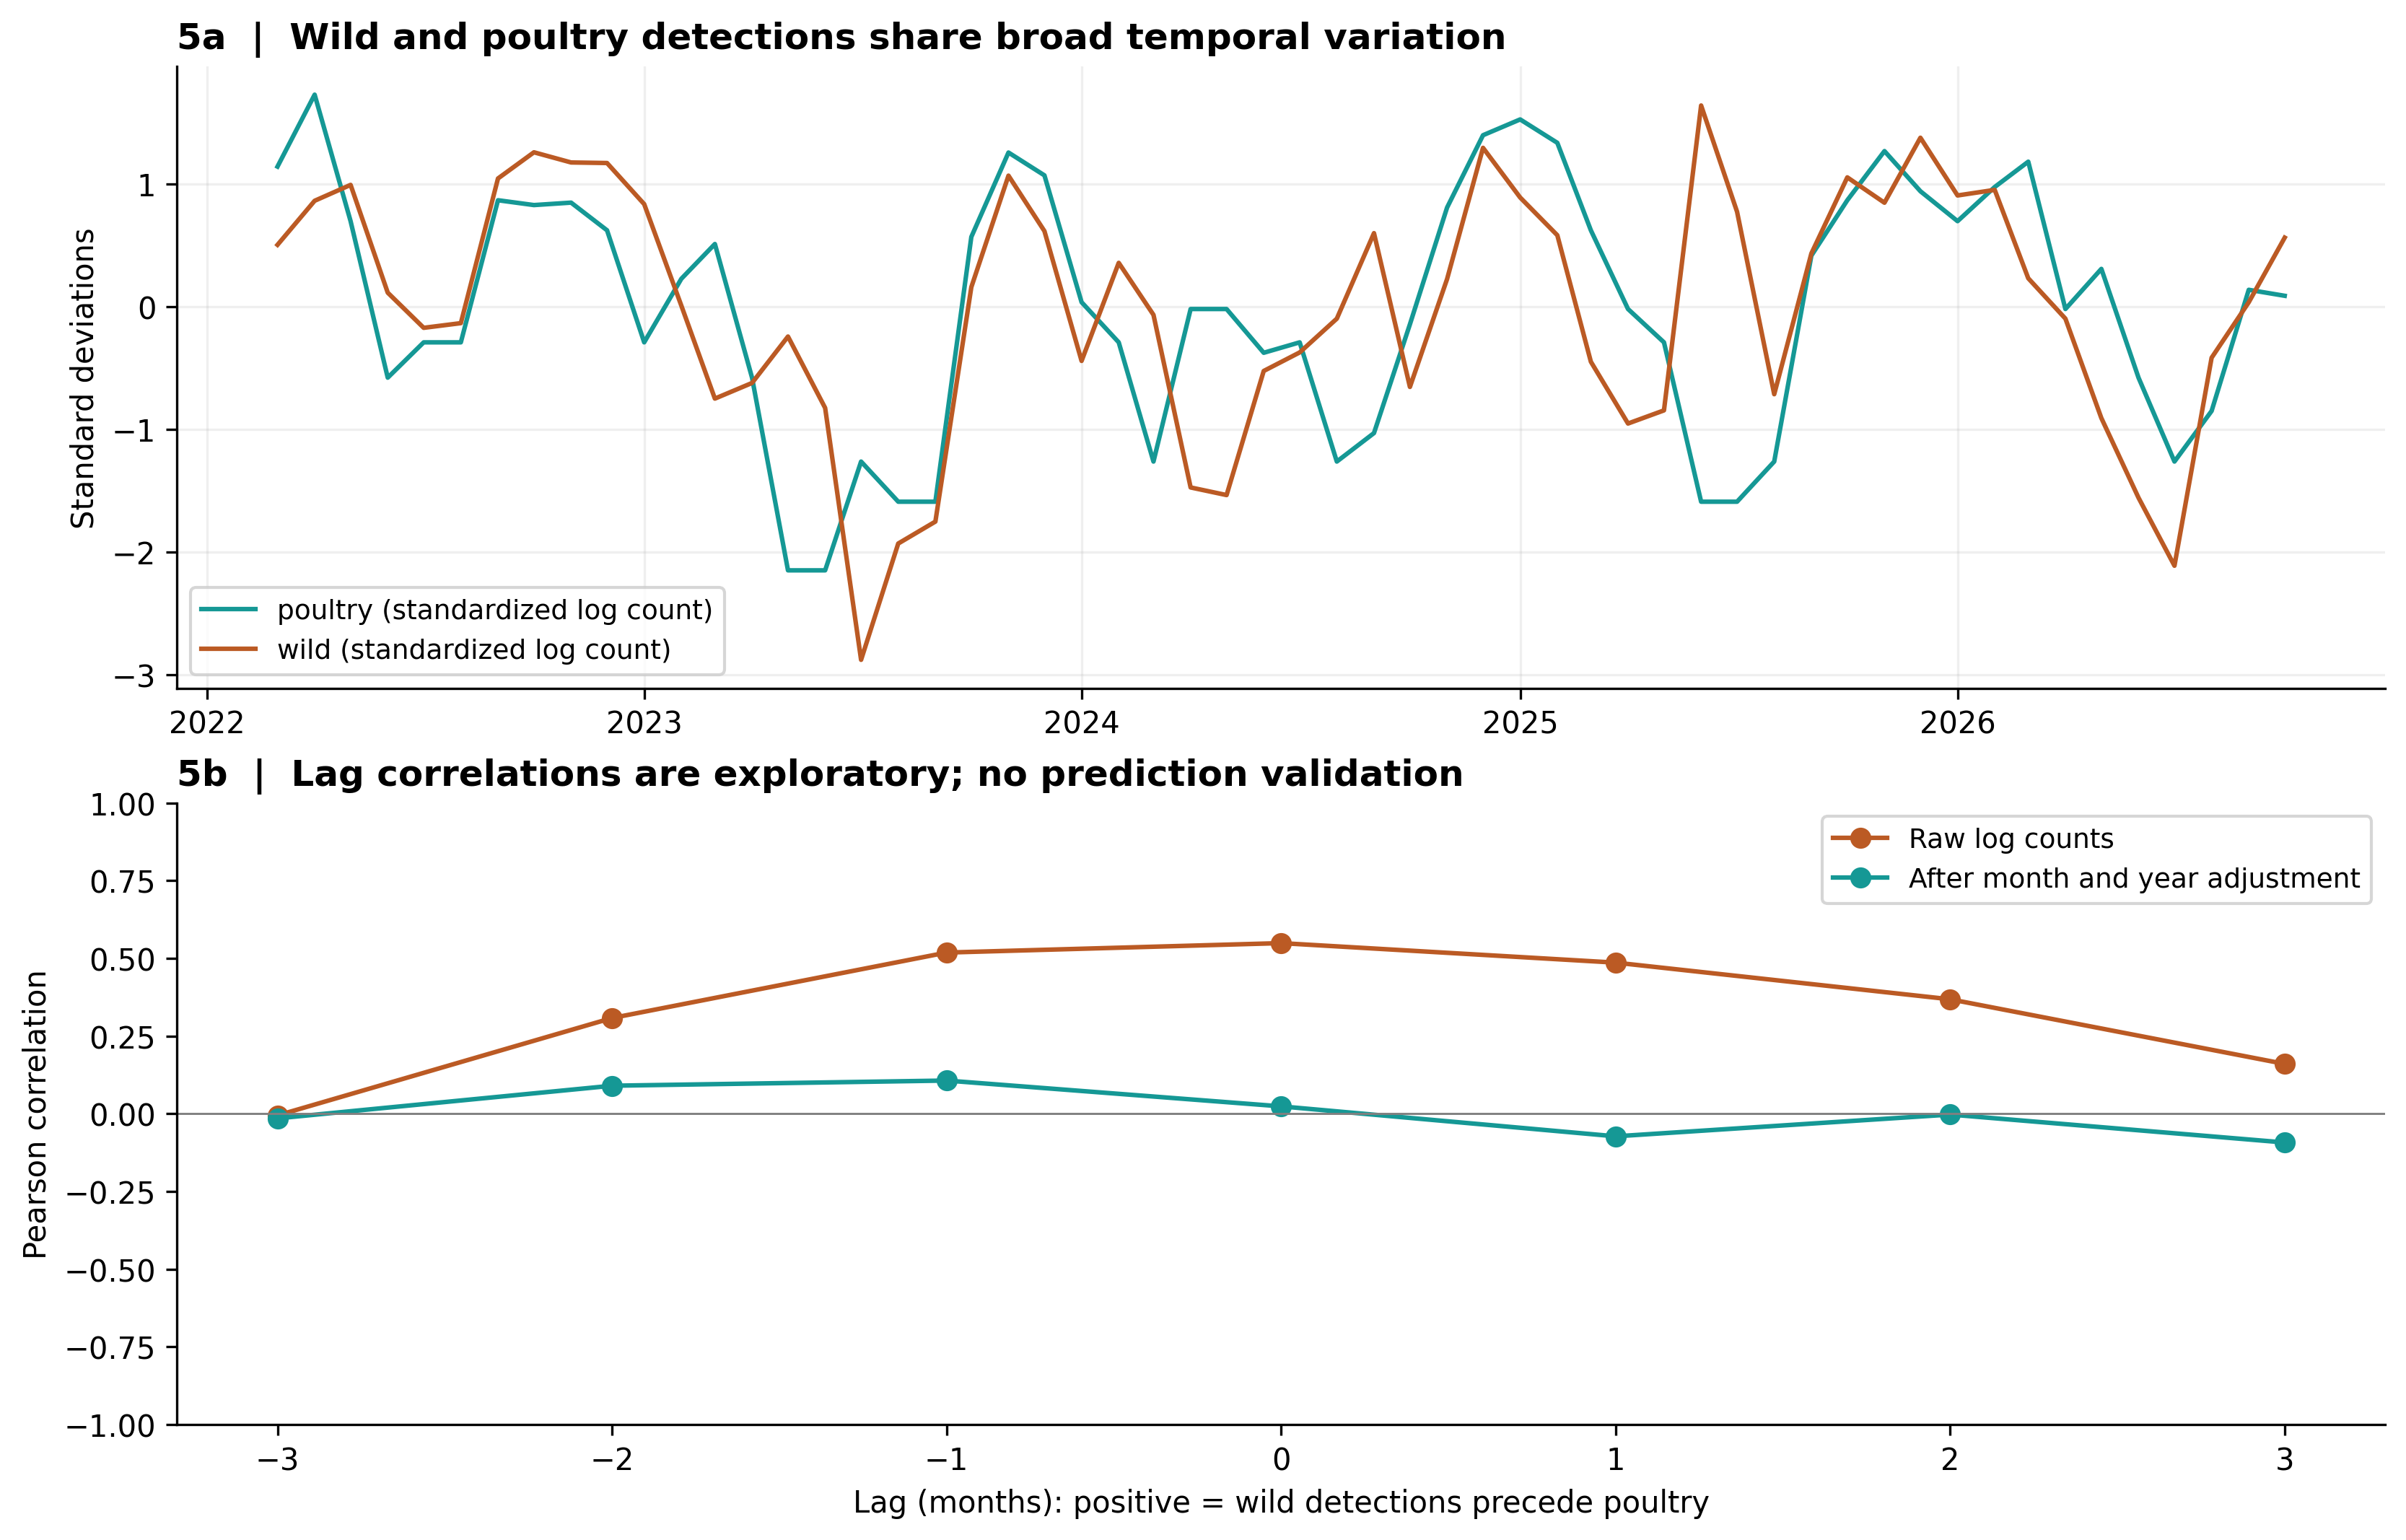

06_burden_concentration.png


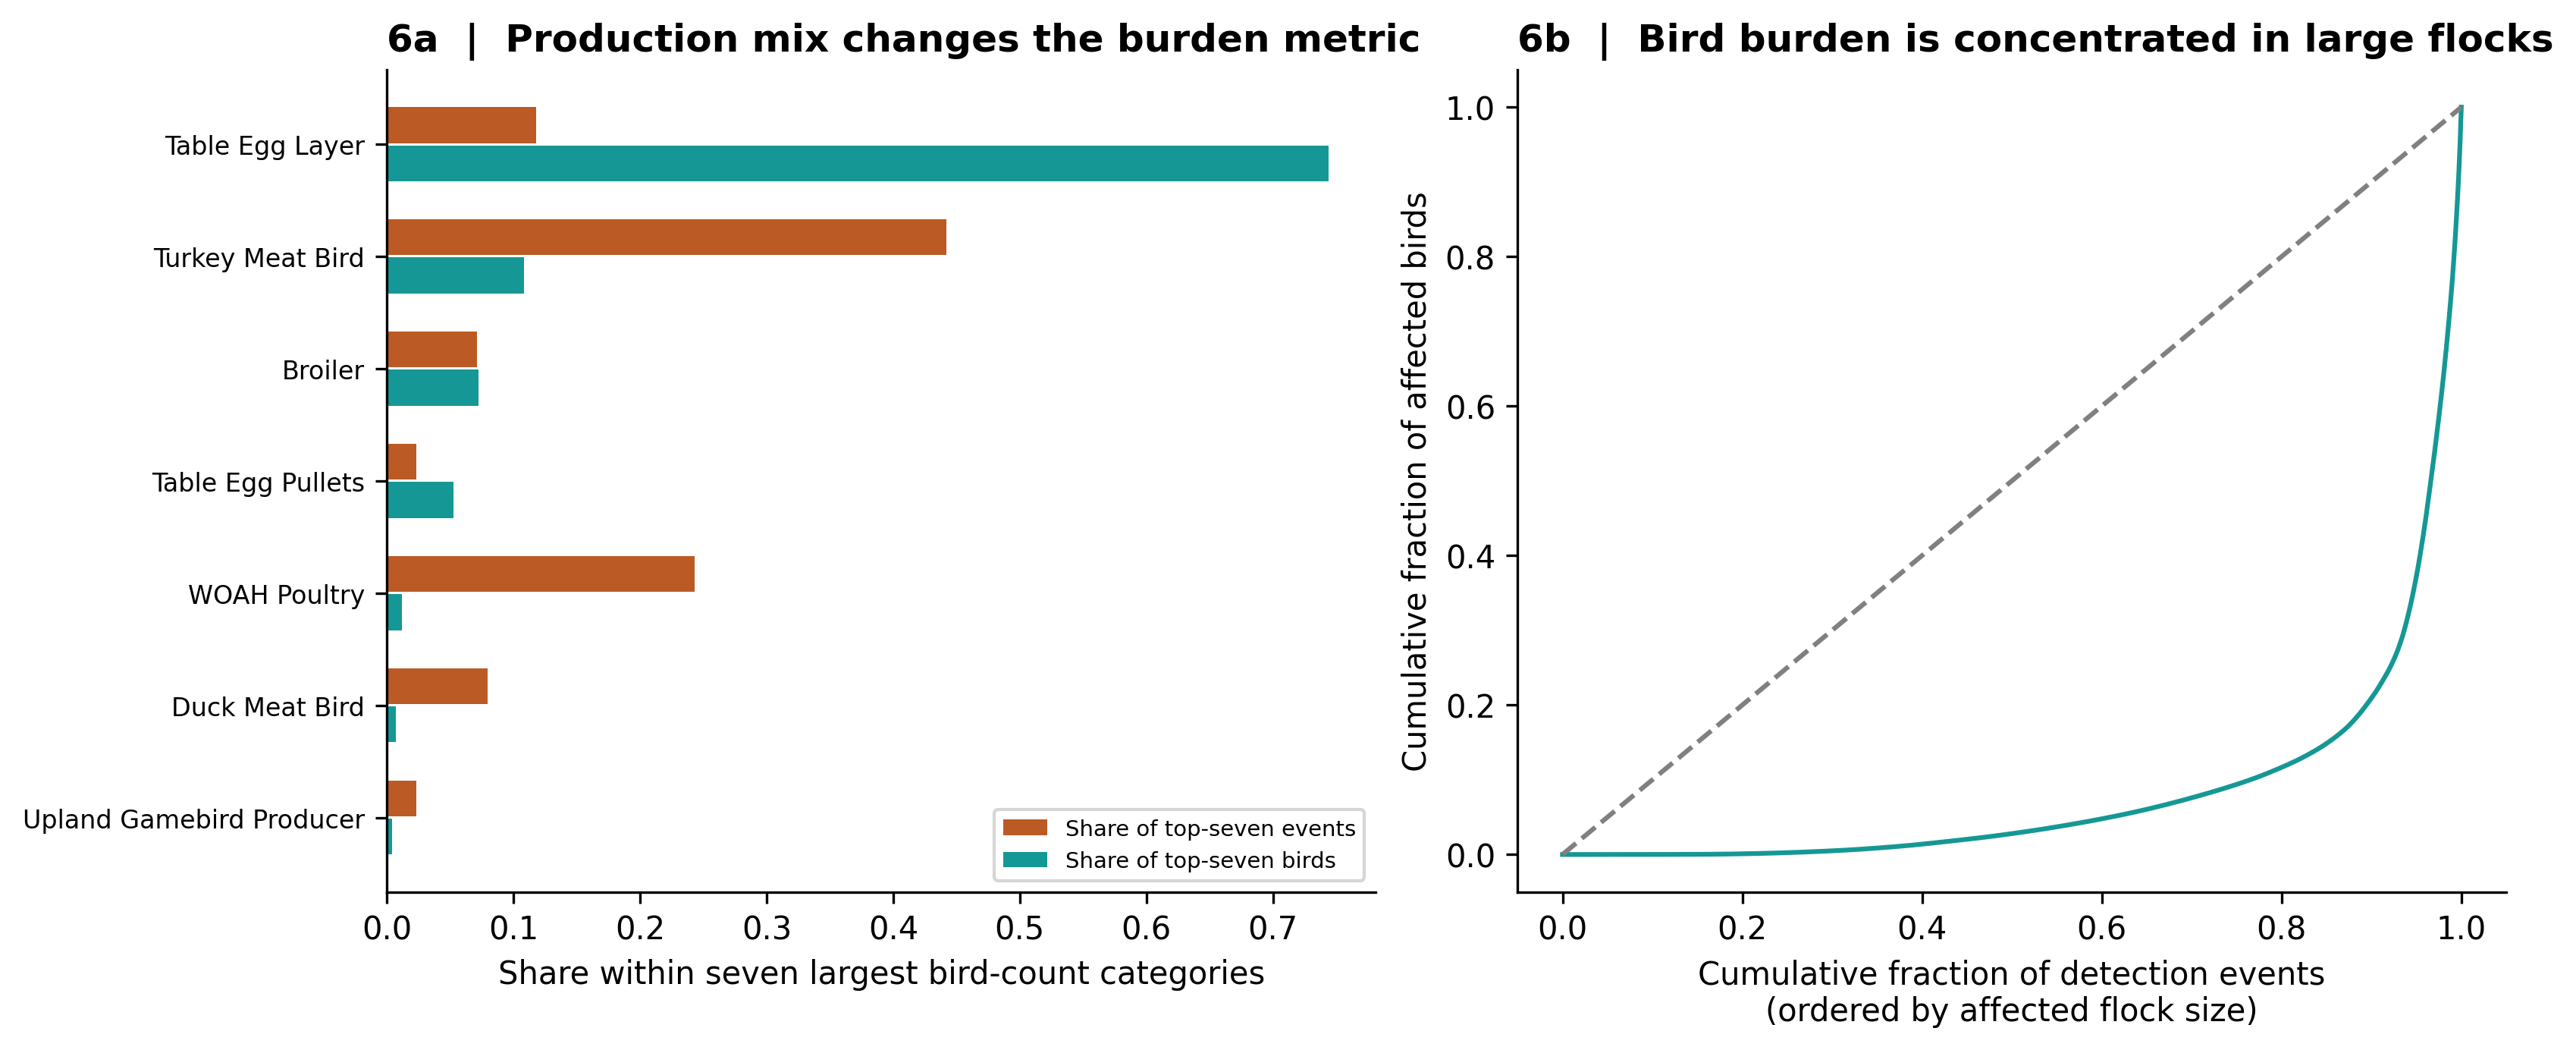

07_surveillance.png


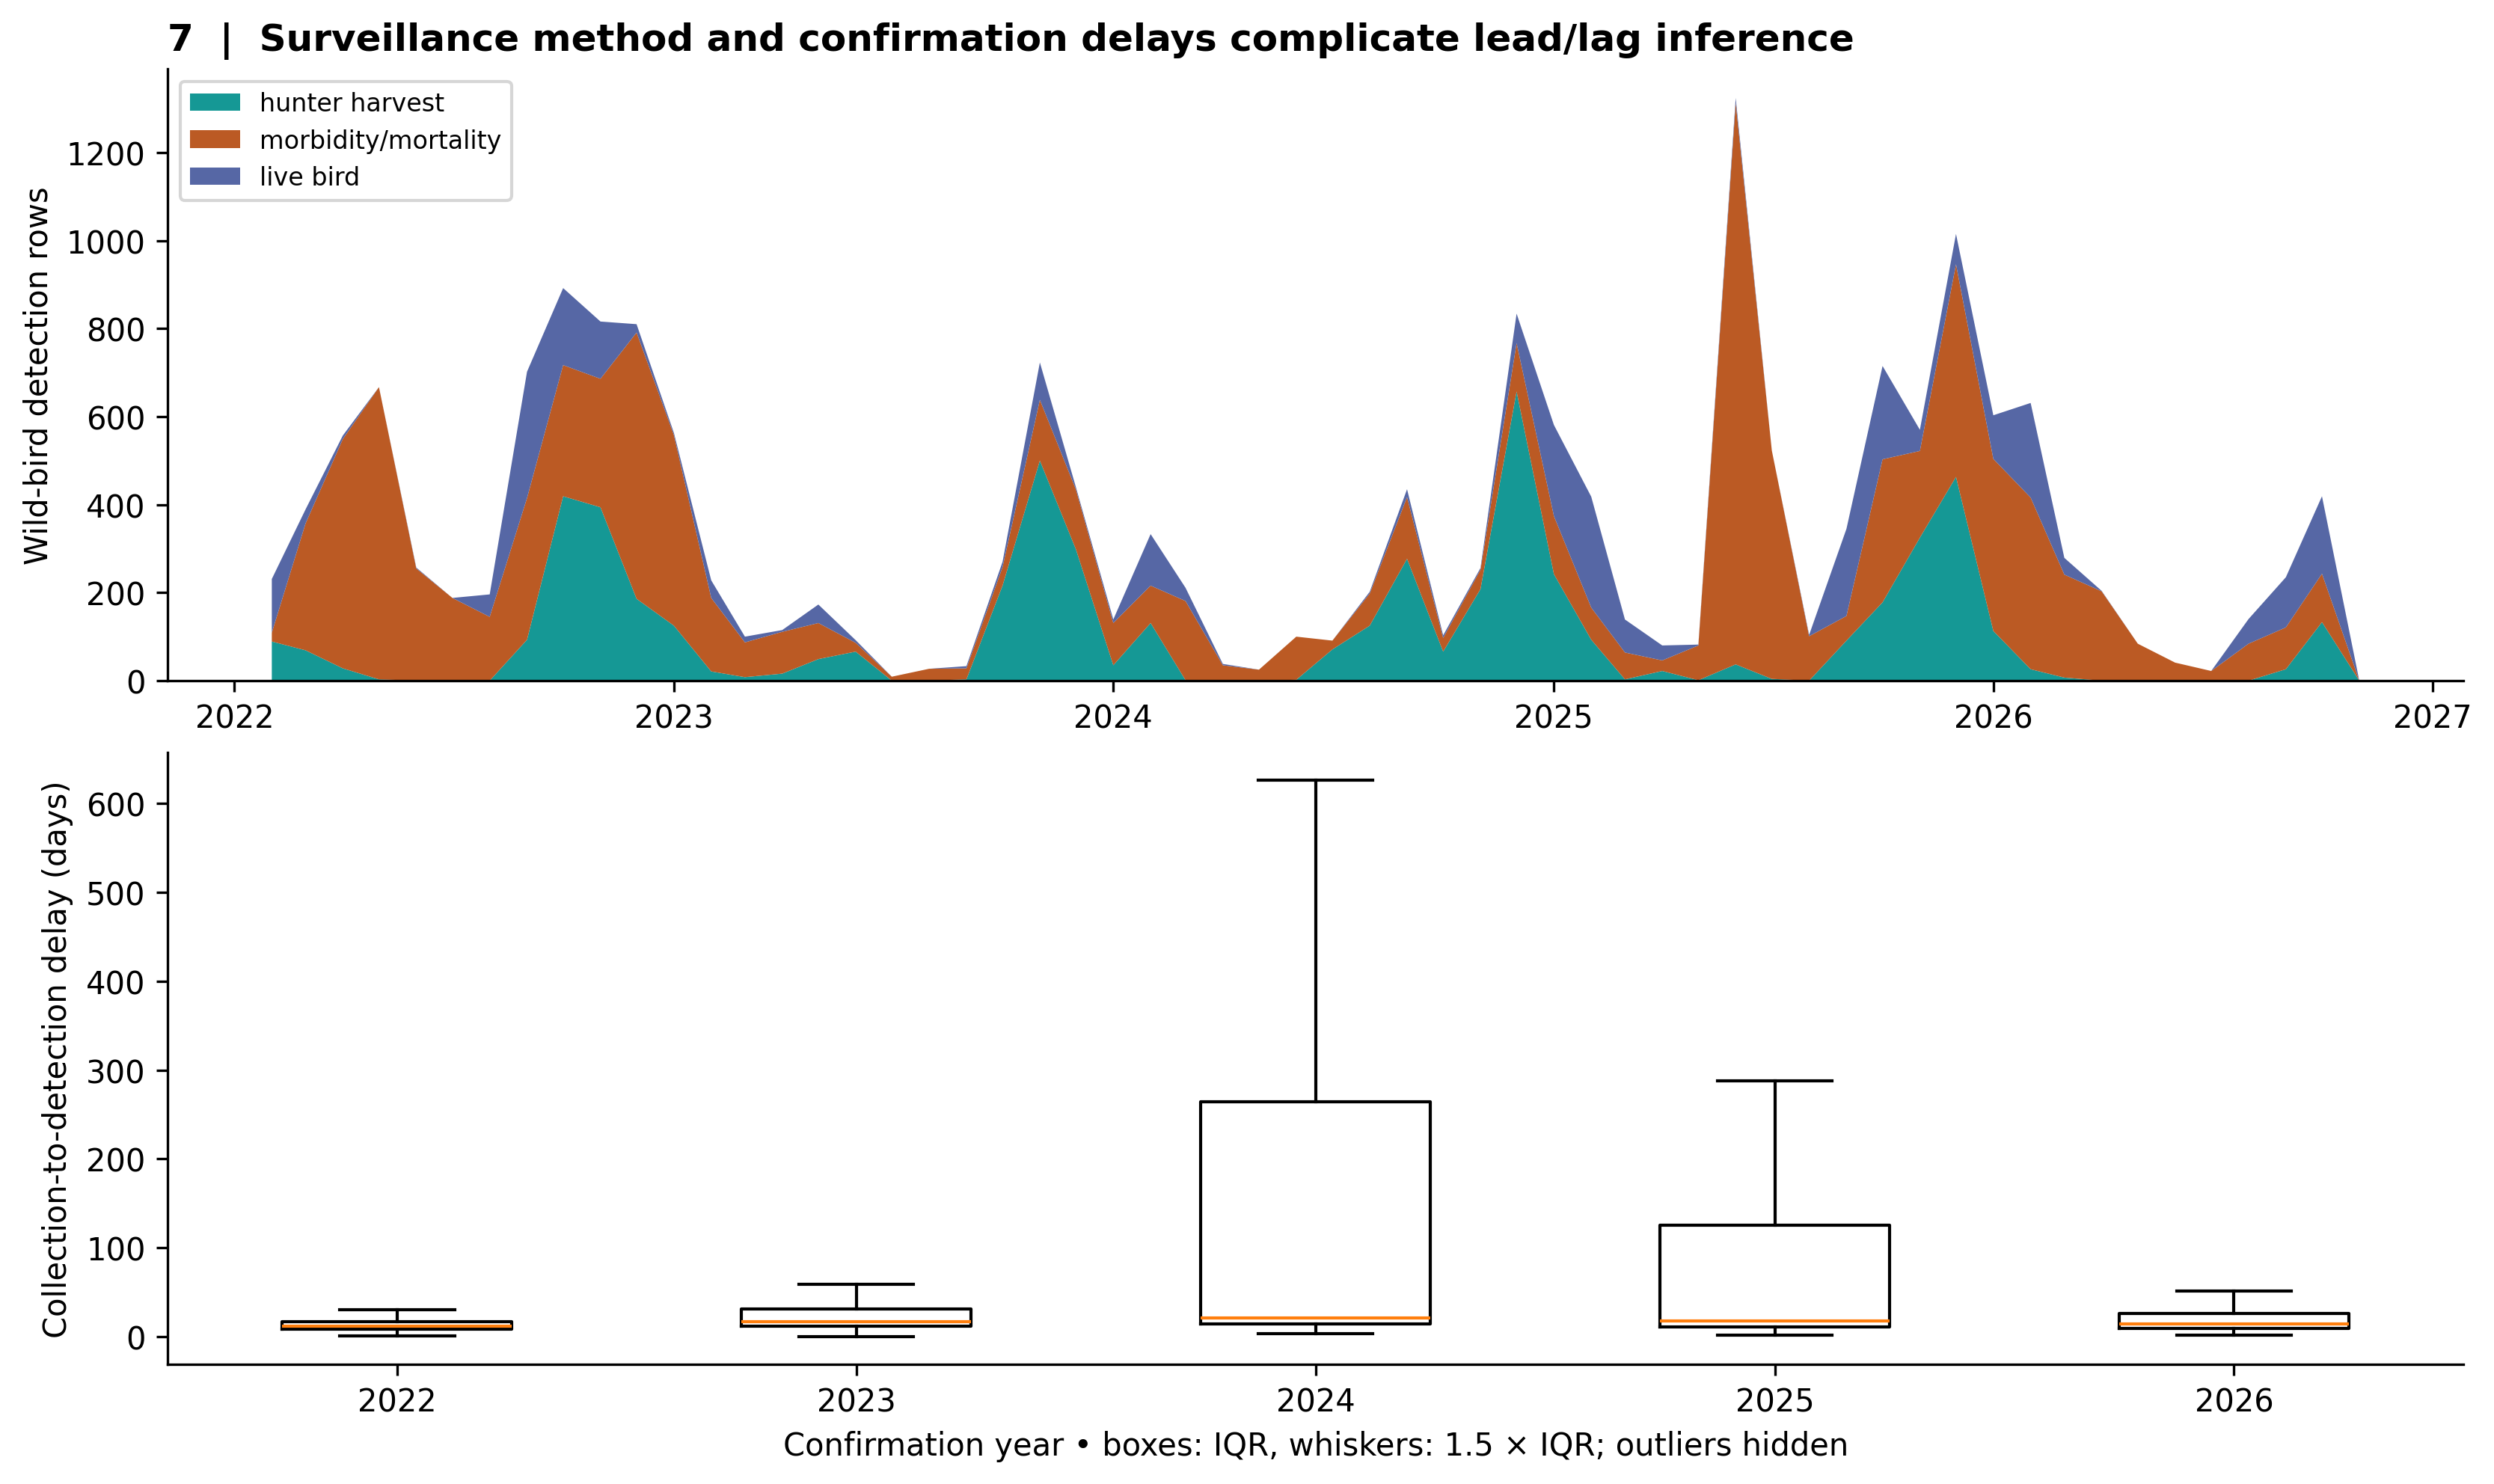

08_state_shares.png


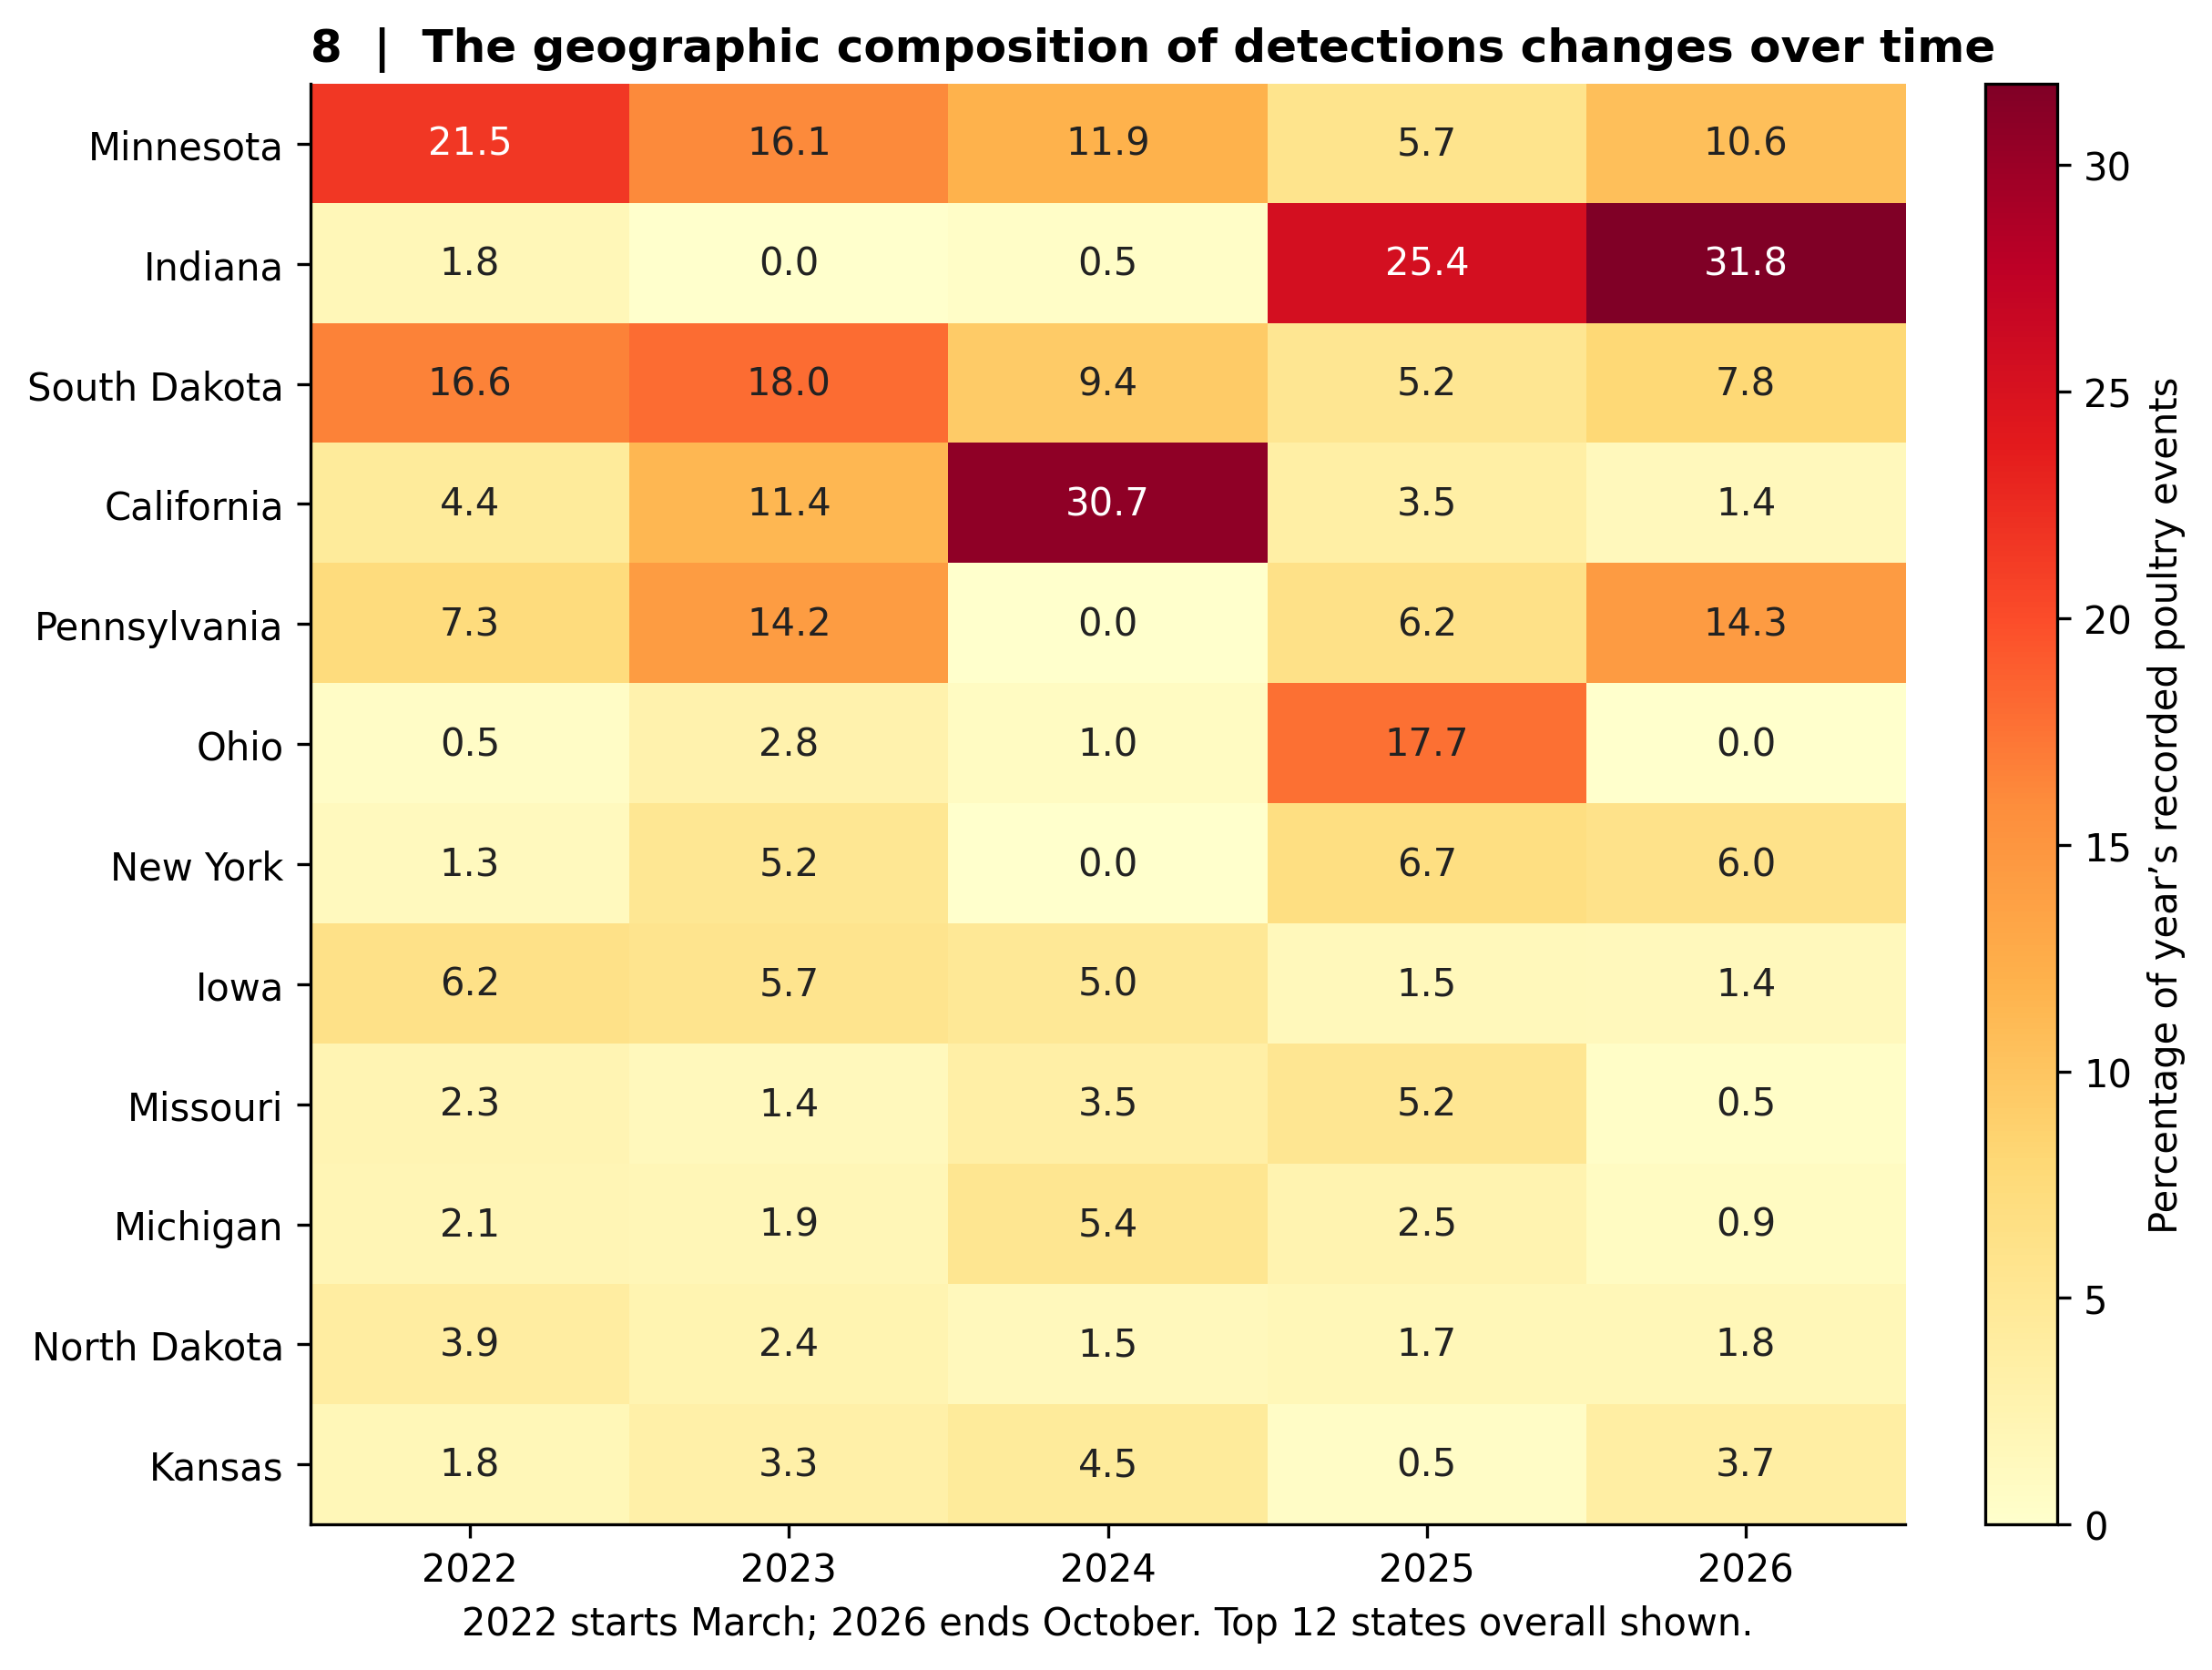

In [6]:
analyze.figures(p, w, m, h)
for path in sorted((ROOT/'figures').glob('*.png')):
    print(path.name)
    display(Image(filename=str(path), width=1000))

## 7. Interpretation and comparison with primary research
The evidence supports a summer lull and changing geographic composition. Pooled production-group differences are not robust to the choice of years. The adjusted one-month wildlife lead is not established by these national monthly records. A null association at this resolution does not negate wildlife transmission.

[Damodaran et al., Nature](https://www.nature.com/articles/s41586-025-09737-x) reconstructed repeated wildlife introductions with sequence data; that is a different estimand from national count correlations. [Ssematimba et al., PLoS ONE](https://pmc.ncbi.nlm.nih.gov/articles/PMC11642945/) inferred infection-to-detection intervals using within-flock observations unavailable here. [Harrington et al., Nature Medicine](https://www.nature.com/articles/s41591-026-04300-1) documented D1.1 spread during autumn 2024; our event table cannot assign genotype-specific causes. The [APHIS September 2025 report](https://www.aphis.usda.gov/sites/default/files/hpai-epi-report-fy25-q4.pdf) also documents common-source/lateral and dairy-associated pathways.

Confounding by geography, production, husbandry, weather and surveillance prevents causal attribution. No infection rates or individual-bird mortality estimates are computed.

### Three follow-up questions
1. Can timely county-week wildlife data predict held-out poultry outbreaks beyond a seasonal baseline?
2. Do geographic differences persist with compatible production-specific susceptible-flock denominators?
3. Do winter peaks reflect weather, genotype introductions, dairy-associated transmission or local farm clusters?

The report expands these questions into data requirements and discusses NASS and NOAA sources.

In [7]:
import build_report
build_report.main()
print('Report generated:', (ROOT/'REPORT.html').exists())
print('Figure pairs:', len(list((ROOT/'figures').glob('*.png'))), len(list((ROOT/'figures').glob('*.svg'))))

Wrote REPORT.html
Report generated: True
Figure pairs: 8 8
